# Aula 10 — Laboratório: Pipeline de Limpeza Completo (Prática) · Conteúdo

**Unidade 2 — Aquisição e Preparação de Dados** · ver também: [exercícios](exercicios.ipynb) · [atividades](atividades.ipynb)

**🛠️ Aula 10 — Laboratório: Pipeline de Limpeza Completo (Prática)**

Última aula da Unidade 2 (Aquisição e Preparação de Dados). Pipeline ETL simples; transformação de tipos; engenharia de atributos básica (one-hot encoding, label encoding, binning); exportação do dataset limpo. Prática com **dados sintéticos da área da saúde** — cadastro de pacientes, internações, consultas ambulatoriais e exames laboratoriais de uma rede hospitalar fictícia do RN (nenhum dado é de paciente real). Recursos: Jupyter Notebook, pandas, scikit-learn (preprocessing). Avaliação: **formulário avaliativo com 10 questões** + **entrega do dataset limpo e do notebook documentado** — prazo de ambos até 30/10/2026. O exercício prático é para treino e não precisa ser entregue. Materiais desta aula: livro Tópicos de Estudo (5 capítulos) · apostila completa em PDF · pacote com notebooks e datasets · formulário avaliativo · tarefa de entrega.

---
## Tópicos de Estudo — Aula 10

### 1. Pipeline ETL: dos dados brutos ao dataset limpo

Na Aula 09 corrigimos problemas de qualidade um a um. Num projeto real, essas correções precisam ser **repetíveis**: no mês seguinte chegam novos arquivos e tudo deve rodar de novo. Para isso organizamos o trabalho num **pipeline** — uma sequência fixa de etapas.

#### ETL

- **Extract** — ler as fontes (CSV, JSON de uma API, planilhas, banco de dados) *sem alterá-las*;
- **Transform** — corrigir tipos, padronizar categorias, remover duplicatas, juntar tabelas, criar atributos e codificar categorias;
- **Load** — gravar o resultado no destino (arquivo CSV/Parquet, banco de dados), com documentação.

#### O cenário do laboratório (dados sintéticos)

Uma rede hospitalar fictícia do RN tem dois sistemas: o **cadastro** (`pacientes.csv`, 200 pacientes) e o **sistema de internações**, que entrega um JSON (`internacoes.json`, 304 registros). Nenhum registro é de paciente real.

O primeiro diagnóstico com `dtypes` mostra que **todas** as colunas chegaram como texto — inclusive datas, custos e a coluna de UTI. Além disso há grafias diferentes (`F`, `f`, `Feminino`), 4 internações duplicadas e 3 internações de pacientes que não existem no cadastro.

In [ ]:
pacientes = pd.read_csv(DADOS / "pacientes.csv")
internacoes = pd.read_json(DADOS / "internacoes.json")
internacoes.dtypes        # tudo texto (str/object)

**Boas práticas:** trabalhar em cópias (`df.copy()`), organizar cada etapa em uma função e verificar regras com `assert` — se algo inesperado aparecer, o pipeline para em vez de gerar um dataset errado.

### 2. Transformação de tipos e padronização

#### Datas

Datas em dois formatos (`1993-10-22` e `22/10/1993`) são convertidas com cada formato e combinadas:

In [ ]:
iso = pd.to_datetime(txt, format="%Y-%m-%d", errors="coerce")
br = pd.to_datetime(txt, format="%d/%m/%Y", errors="coerce")
p["data_nascimento"] = iso.fillna(br)      # 185 + 15 = 200 datas

#### Moeda brasileira → número

In [ ]:
(serie.str.replace("R$", "", regex=False).str.strip()
      .str.replace(".", "", regex=False)     # tira o ponto de milhar
      .str.replace(",", ".", regex=False)    # vírgula decimal vira ponto
      .astype(float))                        # "R$ 15.764,91" vira 15764.91

A ordem importa: se a vírgula virar ponto antes de remover os pontos, o separador decimal também some.

#### Texto com número dentro

`"62 anos"` ou `"37 min"`: `s.str.extract(r"(\d+)")[0].astype(int)` pega só os dígitos.

#### Categorias e booleanos

In [ ]:
p["sexo"] = p["sexo"].str.strip().str[0].str.upper()          # F, f, Feminino → F
mapa = {"sim": True, "s": True, "não": False, "nao": False, "n": False}
p["plano_saude"] = p["plano_saude"].str.strip().str.lower().map(mapa)
i["gravidade"] = i["gravidade"].str.capitalize()               # leve → Leve

Com `map`, um valor fora do dicionário vira `NaN` — ótimo para descobrir grafias inesperadas na conferência. Colunas Sim/Não viram booleanas, que ocupam menos memória e deixam claro que só há duas respostas.

### 3. Juntando fontes e engenharia de atributos

#### Junção com verificação

In [ ]:
base = i.merge(p, on="id_paciente", how="left",
               validate="many_to_one", indicator=True)
base["_merge"].value_counts()     # both 297 · left_only 3

- `validate="many_to_one"` confere que cada paciente aparece uma única vez no cadastro;
- `indicator=True` revela internações *órfãs* (paciente inexistente) — um problema de integridade referencial que deve ser registrado e tratado.

#### Atributos derivados

In [ ]:
base["tempo_internacao_dias"] = (base["data_alta"] - base["data_entrada"]).dt.days
base["idade"] = ((base["data_entrada"] - base["data_nascimento"]).dt.days // 365.25).astype(int)

Os 5 custos ausentes foram imputados pela mediana do mesmo diagnóstico e gravidade.

#### Binning (discretização)

|  |  |  |
|----|----|----|
| Função | Como define as faixas | Exemplo da aula |
| `pd.cut` | limites escolhidos por você → quantidades diferentes por faixa | faixas etárias 0-17, 18-39, 40-59, 60-79, 80+ |
| `pd.qcut` | quantis → mesma quantidade por faixa | quartis de custo: Baixo, Médio, Alto, Muito alto (≈74 cada) |

Com os novos atributos, a análise fica direta: o tempo médio de internação é 4,8 dias nos casos leves e 10,9 dias nos graves; a proporção de UTI sobe de 2% para 45%.

### 4. Codificação de variáveis categóricas

Modelos de machine learning trabalham com números. A forma de transformar categorias em números depende do tipo:

|  |  |  |
|----|----|----|
| Tipo | Exemplo | Técnica |
| Nominal (sem ordem) | diagnóstico, município, sexo | one-hot: `pd.get_dummies` / `OneHotEncoder` |
| Ordinal (com ordem) | gravidade: Leve \< Moderada \< Grave | dicionário explícito ou `OrdinalEncoder(categories=[...])` |
| Alvo (o que se quer prever) | UTI sim/não | `LabelEncoder` |

#### One-hot encoding

In [ ]:
pd.get_dummies(base["diagnostico_principal"], prefix="diag", dtype=int)

Cria uma coluna 0/1 por categoria, sem criar ordem. Numerar diagnósticos (0 a 4) faria um modelo "achar" que existe uma ordem — e até médias — entre eles.

**Armadilha da variável dummy:** as colunas sempre somam 1, então uma delas é redundante. Com `drop_first=True`, município gera 3 colunas e Caicó vira a referência (todas 0).

#### Label encoding × codificação ordinal

O `LabelEncoder` numera em **ordem alfabética**: Grave = 0, Leve = 1, Moderada = 2 — que não é a ordem clínica. Para atributos ordinais, informe a ordem:

In [ ]:
ordem = {"Leve": 0, "Moderada": 1, "Grave": 2}
base["gravidade_cod"] = base["gravidade"].map(ordem)
# ou: OrdinalEncoder(categories=[["Leve", "Moderada", "Grave"]])

### 5. Pipeline do scikit-learn, exportação e documentação

#### ColumnTransformer + Pipeline

In [ ]:
preprocessador = ColumnTransformer([
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominais),
    ("ordinal", OrdinalEncoder(categories=[["Leve", "Moderada", "Grave"]]), ["gravidade"]),
    ("escala", StandardScaler(), ["idade", "tempo_internacao_dias"]),
])
pipeline = Pipeline([("preprocessamento", preprocessador)])
Xt_treino = pipeline.fit_transform(X_treino)   # aprende SÓ com o treino
Xt_teste = pipeline.transform(X_teste)         # aplica ao teste

- **Vazamento de dados (data leakage):** médias, desvios e listas de categorias devem ser aprendidos apenas no treino; o teste só recebe `transform`.
- `handle_unknown="ignore"`: uma categoria nova (ex.: município Assu) vira zeros em vez de erro.

#### Load: CSV × Parquet

|  |  |  |
|----|----|----|
|   | CSV | Parquet |
| Formato | texto, universal | binário, colunar, compactado |
| Tipos | perdidos (datas e categorias voltam como texto) | preservados |
| Tamanho no laboratório | 42 KB | 27 KB |

#### Dicionário de dados

Todo dataset limpo deve ir acompanhado de um dicionário: **coluna, tipo, descrição e transformação aplicada** (ex.: "custo_total — float — texto convertido; 5 ausentes imputados pela mediana do diagnóstico e gravidade").

#### Atividade de entrega

Aplique o pipeline completo ao arquivo `exames_laboratoriais.csv` e entregue o dataset limpo e o notebook documentado na Tarefa da aula (prazo 30/10/2026). Os requisitos e critérios estão na apostila e no notebook-modelo.

---
## Conteúdo — Aula 10 (PDF)

> Convertido de [`Aula10_Pipeline_de_Limpeza_Completo.pdf`](Aula10_Pipeline_de_Limpeza_Completo.pdf) (o original está nesta pasta — confira nele figuras e diagramação).

INSTITUTO FEDERAL DE EDUCAÇÃO, CIÊNCIA E TECNOLOGIA DO RIO GRANDE DO NORTE ESPECIALIZAÇÃO EM CIÊNCIA DE DADOS  ·  DISCIPLINA: ANÁLISE E CIÊNCIA DE DADOS

### Aula 10 - Laboratório: Pipeline de Limpeza Completo

Pipeline ETL simples; transformação de tipos; engenharia de atributos básica (one-hot encoding, label encoding, binning); exportação do dataset limpo

Unidade

Natureza Unidade 2 - Aquisição e Preparação de Dados (Aula 10, última aula da unidade)

Aula prática (laboratório)

Carga horária

4 h/a - 1 h de exposição guiada + 3 h de laboratório

Pré-

requisitos

Recursos

Avaliação

Professor Aulas 04-05 (Pandas), 06-08 (aquisição de dados) e 09 (qualidade e limpeza)

Jupyter Notebook/Lab, pandas , numpy , scikit-learn ( preprocessing , compose , pipeline ), pyarrow ; dados sintéticos da área da saúde

Formulário avaliativo (10 questões) + entrega de dataset limpo e notebook documentado - prazo 30/10/2026. O exercício prático é para treino e não precisa ser entregue.

Plácido Antônio de Souza Neto

### Objetivos de aprendizagem

Ao final desta aula, espera-se que o estudante seja capaz de:

1. Organizar a preparação de dados como um pipeline ETL (extrair, transformar, carregar) repetível e verificável.
2. Converter tipos : textos de datas, valores monetários, números com unidade e respostas Sim/Não.
3. Juntar fontes com merge , verificando a relação entre as tabelas e registros órfãos.
4. Criar atributos derivados e discretizar variáveis numéricas com pd.cut e pd.qcut .
5. Codificar categorias com one-hot, codificação ordinal e label encoding, escolhendo a técnica adequada a cada tipo de variável.
6. Montar um pré-processamento com ColumnTransformer e Pipeline do scikit-learn sem vazamento de dados.
7. Exportar o dataset limpo (CSV e Parquet) acompanhado de um dicionário de dados.

### Sumário

### Parte I - Fundamentos

- 1.1 O que é um pipeline ETL
- 1.2 Transformação de tipos

- 1.3 Padronização e validação
- 1.4 Juntando fontes de dados
- 1.5 Engenharia de atributos e binning
- 1.6 Codificação de variáveis categóricas
- 1.7 Pré-processamento com scikit-learn
- 1.8 Exportação e documentação

Parte II - Laboratório guiado: internações hospitalares

Parte III - Exercício prático: consultas ambulatoriais (sem entrega)

Parte IV - Atividade de entrega: exames laboratoriais

Parte V - Formulário avaliativo

Apêndice A - Colinha do pipeline

Apêndice B - Referências

### SOBRE OS DADOS USADOS NESTA AULA

Todos os conjuntos desta aula são sintéticos : foram sorteados por um script Python com semente fixa ( gerar\_dados.py , incluído no pacote) e não correspondem a nenhum paciente real . Eles imitam dados de uma rede hospitalar fictícia do RN - cadastro de pacientes, internações, consultas ambulatoriais e exames laboratoriais - com problemas inseridos de propósito, em quantidades conhecidas. Dados de saúde reais são dados pessoais sensíveis pela LGPD (art. 5º, II) e exigem anonimização, controle de acesso e base legal para tratamento.

### Parte I - Fundamentos

Da coleção de correções avulsas a um processo organizado, repetível e documentado

### 1.1 O que é um pipeline ETL

Na Aula 09 corrigimos problemas de qualidade um de cada vez. Em um projeto real, os dados chegam de novo a cada semana ou mês, e as mesmas correções precisam ser aplicadas sempre, do mesmo jeito. Um pipeline é uma sequência fixa de etapas que leva os dados brutos até um dataset pronto para análise. O modelo mais conhecido é o ETL :

| Etapa | O que faz | No laboratório |
|------------|---------------------------------------------------------------------------------------------------------|------------------------------------------------------------------|
| E xtract | lê as fontes, sem alterá-las | read_csv do cadastro e read_json das internações |
| T ransform | corrige tipos, padroniza, remove duplicatas, junta tabelas, cria atributos, codifica categorias, valida | datas, moeda, booleanos, merge , idade, faixas, one-hot, ordinal |
| L oad | grava o resultado no destino, com documentação | CSV + Parquet + dicionário de dados |

Três princípios guiam um bom pipeline:

- Fontes intocadas - o arquivo original nunca é alterado; tudo acontece em cópias.

- Repetibilidade - cada etapa vira uma função; rodar de novo, com dados novos, é um comando.
- Verificação - regras do domínio são checadas com assert ; se algo inesperado aparecer, o pipeline para e avisa, em vez de produzir silenciosamente um dataset errado.

### ETL OU ELT?

Em ambientes de big data é comum o ELT : os dados brutos são carregados primeiro em um data warehouse ou data lake e transformados lá dentro. A ideia é a mesma - só muda onde a transformação acontece.

### 1.2 Transformação de tipos

O primeiro diagnóstico de qualquer pipeline é o dtypes . No laboratório, todas as colunas chegaram como texto. Com texto não é possível calcular tempo de internação, somar custos ou treinar um modelo. As conversões mais comuns:

| Situação | Exemplo | Conversão |
|------------------------|-------------------------|-------------------------------------------------------------------------|
| Data em um formato | 2026-05-26 | pd.to_datetime(s, format="%Y-%m-%d") |
| Datas em dois formatos | 1993-10-22 e 22/10/1993 | converter com cada formato ( errors="coerce" ) e combinar com fillna |
| Moeda brasileira | R$ 15.764,91 | tirar "R$" → tirar ponto de milhar → vírgula vira ponto → astype(float) |
| Número com unidade | 62 anos , 37 min | s.str.extract(r"(\d+)")[0].astype(int) |
| Decimal com vírgula | 84,2 | s.str.replace(",", ".").astype(float) |
| Sim/Não | S , sim , NÃO , nao | map para True / False |

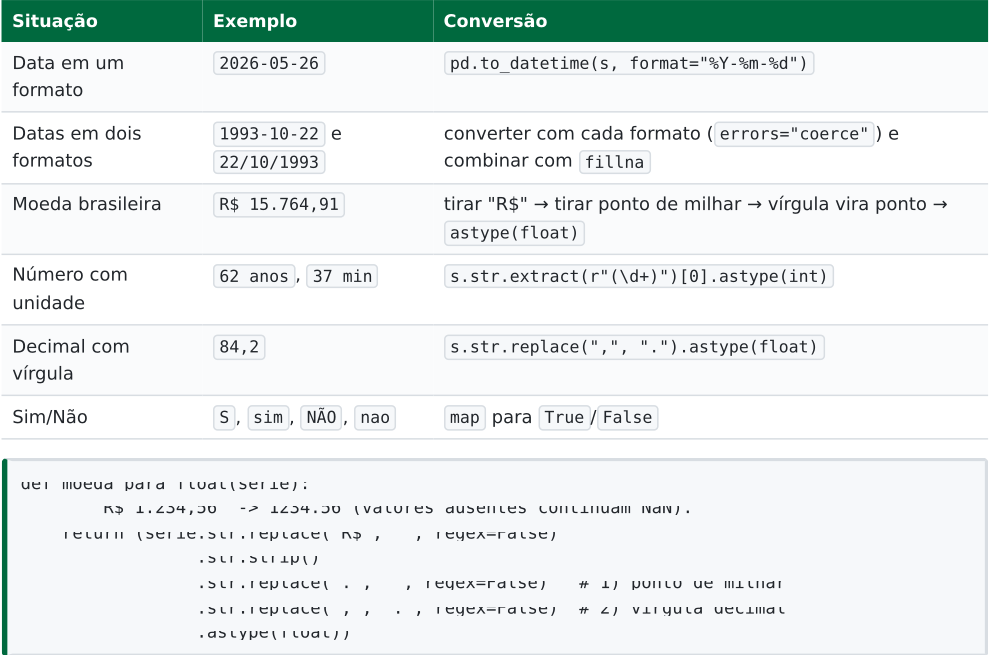

### CUIDADO COM A ORDEM

Se a vírgula virar ponto antes de removermos os pontos de milhar, o separador decimal também é apagado e "R$ 15.764,91" vira 1576491. Sempre confira algumas linhas e um describe() depois de converter.

### 1.3 Padronização e validação

Padronizar é garantir que o mesmo valor seja escrito sempre do mesmo jeito. As ferramentas são as da Aula 09 ( str.strip , str.capitalize , str.upper ) mais os dicionários de mapeamento :

In [ ]:
p["sexo"] = p["sexo"].str.strip().str[0].str.upper()          # F, f, Feminino → F
mapa = {"sim": True, "s": True, "não": False, "nao": False, "n": False}
p["plano_saude"] = p["plano_saude"].str.strip().str.lower().map(mapa)
p["escolaridade"] = p["escolaridade"].str.capitalize().fillna("Não informado")

Com map , um valor que não está no dicionário vira NaN . Isso é uma vantagem: uma grafia nova não passa despercebida. Depois de transformar, valide :

In [ ]:
assert (i["data_alta"] >= i["data_entrada"]).all(), "alta antes da entrada!"
assert i["gravidade"].isin(["Leve", "Moderada", "Grave"]).all()
assert p["id_paciente"].is_unique

### 1.4 Juntando fontes de dados

Dados de sistemas diferentes se ligam por uma chave (aqui, id\_paciente ). O merge do Pandas tem dois parâmetros que transformam a junção em uma verificação de qualidade:

In [ ]:
base = internacoes.merge(pacientes, on="id_paciente", how="left",
                         validate="many_to_one", indicator=True)
base["_merge"].value_counts()      # both 297 · left_only 3 · right_only 0

- validate="many\_to\_one" - várias internações para um paciente; se o cadastro tivesse um paciente repetido, o merge pararia com erro (evitando linhas multiplicadas).
- indicator=True - cria \_merge , que mostra a origem de cada linha. As 3 linhas left\_only são internações de pacientes inexistentes no cadastro (PAC-9001 a PAC-9003): um problema de integridade referencial .

| how= | | Mantém |
|---------|---------|------------------------------------------------------------------------------|
| "inner" | | só as linhas com chave nas duas tabelas |
| "left" | | todas as linhas da tabela da esquerda (ausentes onde não há correspondência) |
| "right" | "outer" | todas da direita / todas de ambas |

### 1.5 Engenharia de atributos e binning

Engenharia de atributos ( feature engineering ) é criar colunas novas, mais úteis para a análise ou para um modelo, a partir das existentes:

In [ ]:
base["tempo_internacao_dias"] = (base["data_alta"] - base["data_entrada"]).dt.days
base["idade"] = ((base["data_entrada"] - base["data_nascimento"]).dt.days //
365.25).astype(int)
base["mes_entrada"] = base["data_entrada"].dt.month
base["custo_por_dia"] = base["custo_total"] / base["tempo_internacao_dias"]

### Binning (discretização)

Transformar um número contínuo em faixas facilita a leitura, reduz o efeito de valores extremos e permite comparações entre grupos.

| Função | Como define as faixas | Resultado no laboratório |
|----------|-----------------------------------------------------------------|------------------------------------------------------------------------|
| pd.cut | limites escolhidos por você → faixas com quantidades diferentes | faixas etárias 0-17 (37), 18-39 (83), 40-59 (62), 60-79 (59), 80+ (56) |
| pd.qcut | quantis → faixas com aproximadamente a mesma quantidade | quartis de custo: Baixo (75), Médio, Alto e Muito alto (74 cada) |

In [ ]:
pd.cut(base["idade"], bins=[0, 18, 40, 60, 80, 120],
       labels=["0-17", "18-39", "40-59", "60-79", "80+"], right=False)
pd.qcut(base["custo_total"], q=4, labels=["Baixo", "Médio", "Alto", "Muito alto"])

Em pd.cut , o padrão right=True fecha o intervalo à direita - (15, 30] inclui o 30. Com right=False o intervalo é [18, 40): inclui 18 e exclui 40, o que é o natural para idades.

### 1.6 Codificação de variáveis categóricas

Algoritmos de machine learning trabalham com números. A técnica de codificação depende do tipo da variável:

| Tipo | Exemplos | Técnica |
|----------------------------|---------------------------------------------------------------|----------------------------------------------------------|
| Nominal - sem ordem | diagnóstico, município, sexo | one-hot ( pd.get_dummies , OneHotEncoder |
| Ordinal - com ordem | gravidade (Leve < Moderada < Grave), escolaridade, satisfação | dicionário explícito ou OrdinalEncoder(categories=[...]) |
| Alvo - a variável a prever | passou pela UTI? (sim/não) | LabelEncoder |

### One-hot encoding

Cria uma coluna 0/1 para cada categoria. Nenhuma categoria fica "maior" que outra.

In [ ]:
pd.get_dummies(base["diagnostico_principal"], prefix="diag", dtype=int)
# diag_AVC  diag_Fratura de fêmur  diag_Infecção urinária  diag_Insuficiência cardíaca
diag_Pneumonia
#    0               0                      1                        0
0

Por que não numerar os diagnósticos de 0 a 4? Porque um modelo interpretaria uma ordem e distâncias que não existem - como se a "média" entre AVC (0) e Infecção urinária (2) fosse Fratura de fêmur (1).

Armadilha da variável dummy. As colunas one-hot sempre somam 1, então qualquer uma pode ser deduzida das demais. Em modelos lineares isso gera redundância (multicolinearidade perfeita); a solução usual é drop\_first=True : município (4 categorias) gera 3 colunas e Caicó vira a categoria de referência (todas as colunas iguais a 0).

### Codificação ordinal e label encoding

```
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
LabelEncoder().fit(base["gravidade"]).classes_     # ['Grave', 'Leve', 'Moderada'] → 0, 1, 2
✘
OrdinalEncoder(categories=[["Leve", "Moderada", "Grave"]])  # Leve=0, Moderada=1, Grave=2  ✔
base["gravidade"].map({"Leve": 0, "Moderada": 1, "Grave": 2})   # equivalente, com Pandas
```

O LabelEncoder numera em ordem alfabética ; ele foi feito para o alvo , onde a numeração é apenas um rótulo. Para atributos ordinais, informe sempre a ordem.

### 1.7 Pré-processamento com scikit-learn

Quando o destino do dataset é um modelo (Unidade 4), o scikit-learn oferece objetos reutilizáveis que aprendem com os dados ( fit ) e depois aplicam o que aprenderam ( transform ):

| Classe | Função |
|----------------------------------------|-----------------------------------------------------------|
| OneHotEncoder(handle_unknown="ignore") | one-hot; categoria nunca vista vira zeros em vez de erro |
| OrdinalEncoder(categories=[...]) | codificação ordinal com a ordem informada |
| StandardScaler / MinMaxScaler | padronização / normalização (Aula 09) |
| ColumnTransformer | aplica um transformador diferente a cada grupo de colunas |
| Pipeline | encadeia etapas em um único objeto com fit / transform |

In [ ]:
preprocessador = ColumnTransformer([
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominais),
    ("ordinal", OrdinalEncoder(categories=[["Leve", "Moderada", "Grave"]]), ["gravidade"]),
    ("escala", StandardScaler(), ["idade", "tempo_internacao_dias"]),
])
pipeline = Pipeline([("preprocessamento", preprocessador)])
X_treino, X_teste = train_test_split(X, test_size=0.25, random_state=42)
Xt_treino = pipeline.fit_transform(X_treino)   # aprende SÓ com o treino
Xt_teste = pipeline.transform(X_teste)         # só aplica no teste

### VAZAMENTO DE DADOS (DATA LEAKAGE)

Médias, desvios e listas de categorias devem ser aprendidos somente no treino . Se o fit usar o conjunto completo, informações do teste "vazam" para o pré-processamento e a avaliação do modelo fica otimista demais. No laboratório, depois de escalar, a média da idade é exatamente 0 no treino e -0,07 no teste - é assim que deve ser.

### 1.8 Exportação e documentação

| | CSV | Parquet |
|------------------------|--------------------------------------------------|-----------------------------------------------------------|
| Formato | texto, abre em qualquer ferramenta | binário, colunar e compactado |
| Tipos | não guarda: datas e categorias voltam como texto | preserva todos os tipos |
| Tamanho no laboratório | 42 KB | 27 KB |
| Comando | df.to_csv("x.csv", index=False) | df.to_parquet("x.parquet", index=False) (requer pyarrow ) |

Um dataset limpo deve sempre ser acompanhado de um dicionário de dados - uma tabela com coluna, tipo, descrição e transformação aplicada . Exemplo de linha: custo\_total · float64 · custo em R$ · texto convertido; 5 ausentes imputados pela mediana do diagnóstico e gravidade . Sem ele, quem recebe o arquivo (inclusive você, daqui a seis meses) não sabe o que cada coluna significa nem como foi produzida.

### Parte II - Laboratório guiado: internações hospitalares

Notebook Aula10\_Pipeline\_de\_Limpeza.ipynb - todas as saídas abaixo são reais

O notebook percorre o pipeline completo com dois arquivos: pacientes.csv (200 pacientes)

- e internacoes.json (304 internações). O quadro resume o que cada etapa encontrou e fez:

| Etapa | Problema encontrado | Transformação |
|---------------------|----------------------------------------------------------------------|--------------------------------------------------------------------|
| Extract | todas as colunas como texto | read_csv / read_json , sem alterar as fontes |
| Datas de nascimento | 185 em ISO e 15 em dd/mm/aaaa | dois to_datetime + fillna → 0 falhas |
| Sexo | M, F, f, m, Masculino, Feminino | primeira letra maiúscula → M 111, F 89 |
| Plano de saúde | 8 grafias de Sim/Não | map → booleano (52 com plano) |
| Escolaridade | maiúsculas misturadas, 6 ausentes | capitalize + "Não informado" |
| Internações | 4 duplicatas; gravidade em minúsculas; custo "R$ 15.764,91"; UTI S/N | 304 → 300 linhas; texto → float e bool |
| Junção | 3 internações órfãs (PAC-9001 a 9003) | merge(validate, indicator) → 297 linhas |
| Atributos | - | tempo de internação, idade, mês, custo por dia, 5 custos imputados |
| Binning | - | faixa etária ( cut ) e faixa de custo ( qcut ) |
| Codificação | - | one-hot do diagnóstico; gravidade e escolaridade ordinais |
| Load | - | CSV (42 KB) + Parquet (27 KB) + dicionário de dados - 297 × 25 |

Os atributos novos já contam uma história. Média por gravidade:

```
           tempo_internacao_dias  custo_total   uti
gravidade
Leve                        4.76      5523.36  0.02
Moderada                    6.64      8765.93  0.16
Grave                      10.87     15856.21  0.45
```

E a comparação dos tipos após reler os arquivos exportados mostra a diferença entre os formatos:

```
                     memória relido do CSV relido do Parquet
data_entrada  datetime64[us]           str    datetime64[us]
uti                     bool          bool              bool
faixa_etaria        category           str          category
custo_total          float64       float64           float64
```

O notebook termina reorganizando tudo em funções ( extrair , transformar\_pacientes , transformar\_internacoes , juntar\_e\_enriquecer , validar ) e com o bônus do Pipeline / ColumnTransformer , incluindo o teste com um município desconhecido (Assu).

### Parte III - Exercício prático: consultas ambulatoriais

Notebook Aula10\_Exercicio\_Pratico.ipynb - para treinar, sem entrega

Um mini-pipeline com uma única tabela ( consultas\_ambulatorio.csv , 83 registros), em sete passos. Cada passo traz um bloco "Para conferir" com o resultado esperado:

| # | Passo | Para conferir |
|-----|--------------------------------------------------------------------|-------------------------------------------------------------------------|
| 1 | Carregar; shape , dtypes , duplicatas | 83 × 7; idade, espera e valor como texto; 3 duplicatas |
| 2 | Remover duplicatas; padronizar especialidade e satisfação | 80 linhas; Clínica geral 25, Cardiologia 24, Pediatria 18, Ortopedia 13 |
| 3 | Tipos: data, "62 anos", "37 min", "R$ 200,00" | espera média 34,9 min; soma dos valores R$ 13.100,00 |
| 4 | Binning da espera com pd.cut e dia da semana | até 15: 13 · 16-30: 24 · 31-60: 35 · mais de 60: 8 |
| 5 | Satisfação ordinal (Ruim=0 ... Ótima=3); one- hot da especialidade | satisfação média 1,42; 14 colunas |
| 6 | Satisfação média por faixa de espera | 2,85 → 1,88 → 0,89 → 0,12 |
| 7 | Validar com assert e exportar | arquivo relido: 80 × 14 |


> **Parte avaliativa desta apostila → [atividades.ipynb](atividades.ipynb).**

### Apêndice A - Colinha do pipeline

| Tarefa | Código |
|---------------------|-----------------------------------------------------------------------------------------------------|
| Ler JSON | pd.read_json("arquivo.json") |
| Tipos | df.dtypes · df.astype({"col": float}) |
| Datas (2 formatos) | pd.to_datetime(s, format=f1, errors="coerce").fillna(pd.to_datetime(s, format=f2, errors="coerce")) |
| Dígitos de um texto | s.str.extract(r"(\d+)")[0].astype(int) |
| Mapear valores | s.map({"S": True, "N": False}) |
| Junção verificada | a.merge(b, on="id", how="left", validate="many_to_one", indicator=True) |
| Diferença de datas | (df["fim"] - df["inicio"]).dt.days |
| Faixas por limites | pd.cut(s, bins=[...], labels=[...], right=False) |
| Faixas por quantis | pd.qcut(s, q=4, labels=[...]) |
| One-hot | pd.get_dummies(s, prefix="p", drop_first=True, dtype=int) |
| Ordinal | s.map({"Leve": 0, "Moderada": 1, "Grave": 2}) |
| Validar | assert df["id"].is_unique · assert df.isna().sum().sum() == 0 |
| Exportar | df.to_csv("x.csv", index=False) · df.to_parquet("x.parquet", index=False) |
| sklearn | ColumnTransformer([...]) · Pipeline([...]) · fit_transform (treino) · transform (teste) |

### Apêndice B - Referências

- McKINNEY, Wes. Python para Análise de Dados . 3. ed. São Paulo: Novatec, 2023. Caps. 7 e 8 (limpeza, preparação, junção).
- GÉRON, Aurélien. Mãos à Obra: Aprendizado de Máquina com Scikit-Learn, Keras &amp; TensorFlow . 2. ed. Rio de Janeiro: Alta Books, 2021. Cap. 2 (preparação dos dados e pipelines).
- SCIKIT-LEARN. Preprocessing data . scikit-learn.org/stable/modules/preprocessing.html
- SCIKIT-LEARN. Pipelines and composite estimators . scikitlearn.org/stable/modules/compose.html
- PANDAS. Merge, join, concatenate and compare . pandas.pydata.org/docs/user\_guide/merging.html
- BRASIL. Lei nº 13.709/2018 - Lei Geral de Proteção de Dados Pessoais (LGPD) , art. 5º, II (dados sensíveis).